In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [46]:
df = pd.read_csv('/content/credit_risk_dataset.csv')

In [47]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [49]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [50]:
df.shape

(32581, 12)

In [51]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [52]:
df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

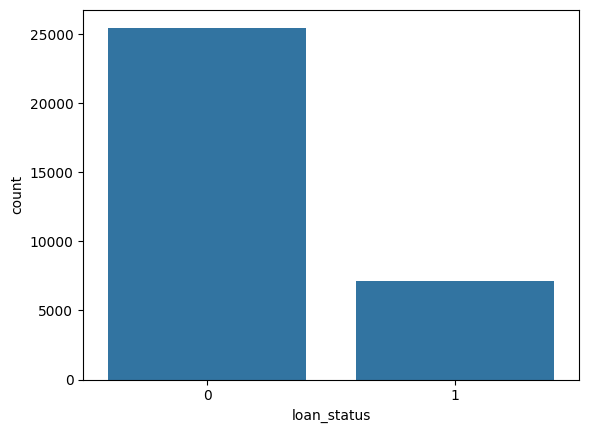

In [53]:
sns.countplot(x= 'loan_status',data = df)

In [54]:
numerical_cols = df.select_dtypes(include='number')

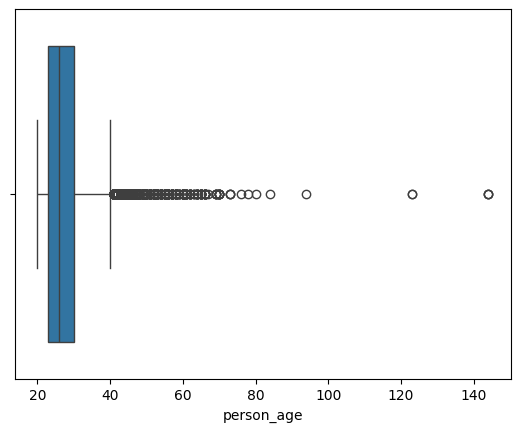

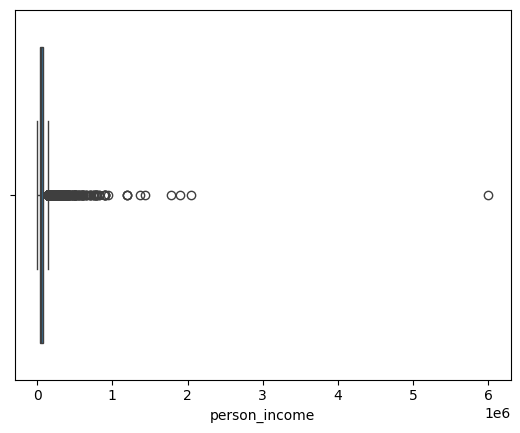

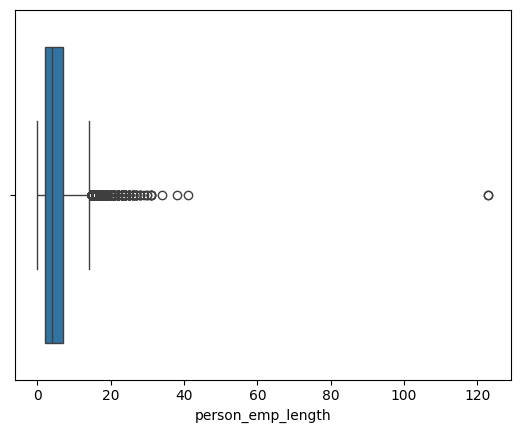

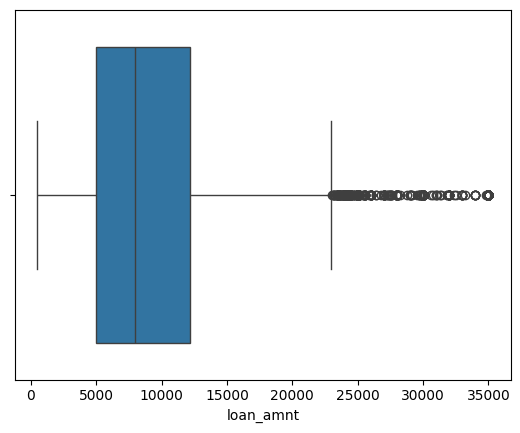

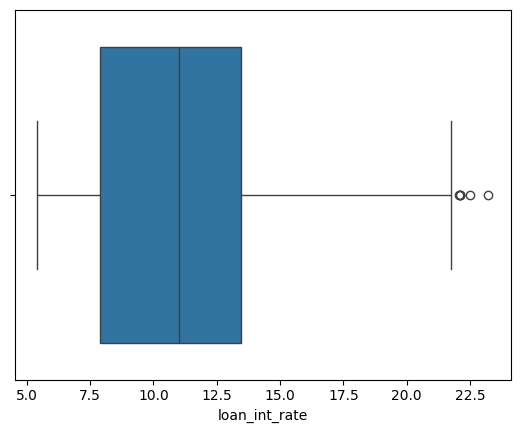

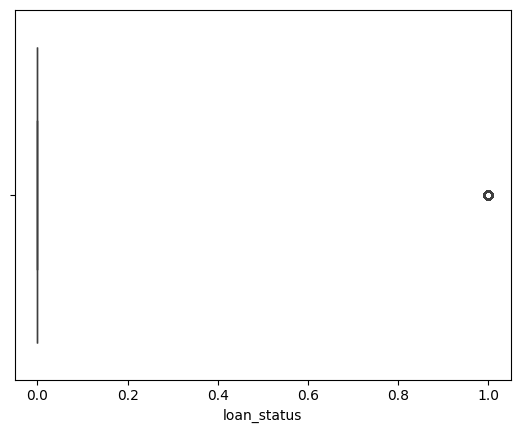

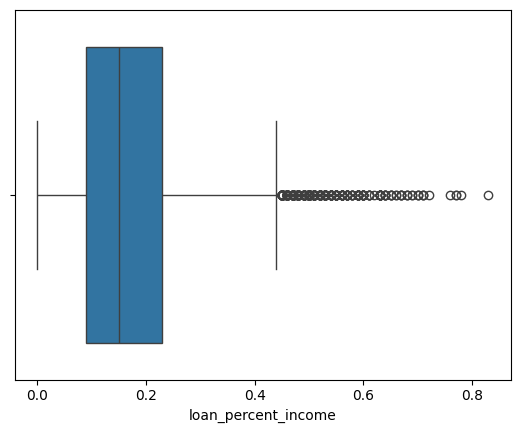

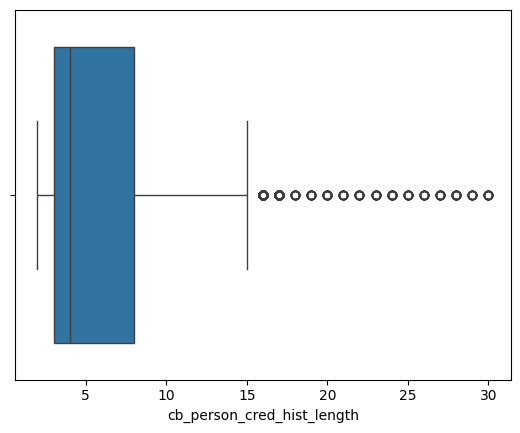

In [55]:
for i in numerical_cols:
  sns.boxplot(x=df[i])
  plt.show()



In [56]:
(df['person_age'] > 100).sum()

np.int64(5)

In [57]:
(df['person_emp_length']  > 60).sum()

np.int64(2)

<Axes: >

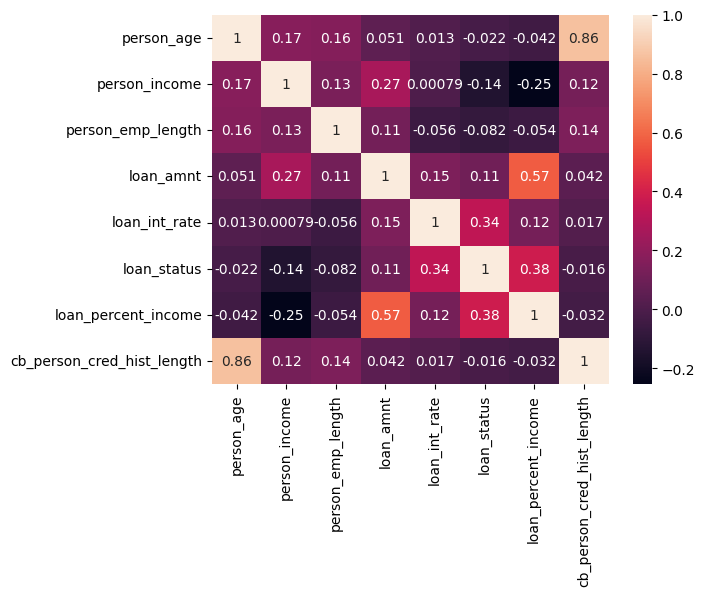

In [58]:
sns.heatmap(df.corr(numeric_only=True),annot = True)

In [59]:

df_copy = df.copy()

# 1. Remove duplicates
print(f"Original shape of the dataset: {df_copy.shape}")

df_copy = df_copy.drop_duplicates()

print(f"After dropping duplicates: {df_copy.shape}")


# 2. Remove ages below 18 and above 100
df_copy = df_copy[
    (df_copy['person_age'] >= 18) &
    (df_copy['person_age'] <= 100)
]


# 3. Remove unrealistic employment length
df_copy = df_copy[
    (df_copy['person_emp_length'] <= df_copy['person_age']) &
    (df_copy['person_emp_length'] <= 60)
]


# 4. Remove invalid loan amounts
df_copy = df_copy[df_copy['loan_amnt'] > 0]


print(f"Final shape after cleaning: {df_copy.shape}")


Original shape of the dataset: (32581, 12)
After dropping duplicates: (32416, 12)
Final shape after cleaning: (31522, 12)


In [60]:
X = df_copy.drop(['loan_status'],axis =1 )
y = df_copy['loan_status']

In [61]:
from sklearn.model_selection import train_test_split

In [62]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

In [63]:
numeric_cols = [
    'person_age',
    'person_income',
    'person_emp_length',
    'loan_amnt',
    'loan_int_rate',
    'loan_percent_income',
    'cb_person_cred_hist_length'
]


categorical_cols = [
    'person_home_ownership',
    'loan_intent',
    'loan_grade',
    'cb_person_default_on_file'
]

In [64]:
neg , pos = np.bincount(y_train)
scale_weight =  neg / pos

In [65]:
scale_weight

np.float64(3.6312213039485766)

In [66]:
# For evaluating our model
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, precision_recall_curve,classification_report


def evaluate_model(model_name,model,X_test,y_test):
    y_pred = model.predict(X_test)
    y_pred_prob = model.predict_proba(X_test)[:,1]


    accuracy = accuracy_score(y_test,y_pred)
    precision = precision_score(y_test,y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    #Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    class_report = classification_report(y_test, y_pred)

    print(f"Accuracy: {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1: {f1:.2f}")
    print()
    print(f"{model_name} Classification Report:")
    print(class_report)


    #Plotting Confusion Matrix
    sns. heatmap(cm, annot=True, fmt="d")
    plt. title(f"{model_name} Confusion Matrix")
    plt.ylabel("Actual Values")
    plt.xlabel("Predicted Values")
    plt.show()


    #Plotting ROC-AUC curve
    precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
    plt.plot(recalls, precisions)
    plt.xlabel('Recall')
    plt.ylabel("Precision")
    plt.title(f"{model_name} Precision-Recall Curve")
    plt.show()

In [67]:
#Logistic Regression : impute + SCALE Numeric, impute + One-Hot-Encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn. impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [68]:
# Logistic Regression


preprocessor_lr = ColumnTransformer(transformers=[
    ('num',Pipeline(steps=[
        ('impute',SimpleImputer(strategy='median')),
        ('scale',StandardScaler())
    ]),numeric_cols),
    ('cat',Pipeline([
        ('inpute',SimpleImputer(strategy='constant',fill_value='Missing')),
        ('encode',OneHotEncoder(handle_unknown='ignore'))
    ]),categorical_cols)
])

In [69]:
# XG boost NO scake


preprocessor_xg = ColumnTransformer(transformers=[
    ('num',Pipeline(steps=[
        ('impute',SimpleImputer(strategy='median'))
    ]),numeric_cols),
    ('cat',Pipeline([
        ('inpute',SimpleImputer(strategy='constant',fill_value='Missing')),
        ('encode',OneHotEncoder(handle_unknown='ignore'))
    ]),categorical_cols)
])

In [70]:
from sklearn.model_selection import StratifiedKFold,cross_validate
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)


scoring = {'roc_auc':'roc_auc', 'accuracy': 'accuracy', 'precision': 'precision', 'recall':'recall','f1':'f1'}

In [71]:


#Logistic Regression
from sklearn. linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
('preprocessor', preprocessor_lr),
("classifier", LogisticRegression(max_iter=1000,class_weight='balanced' , random_state=42))
])

In [72]:
#XGboost Model
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
('preprocessor', preprocessor_xg),
('classifier', XGBClassifier(
n_estimator=300, max_depth=5, learning_rate=0.1,
scale_pos_weight=scale_weight))
])

In [73]:
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ('XGBoost', xgb_cv_pipeline)]:
    cv_result = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    print(cv_name)
    print(f"ROC-AUC : {cv_result['test_roc_auc'].mean()}")
    print(f"Accuracy : {cv_result['test_accuracy'].mean()}")
    print(f"Precision : {cv_result['test_precision'].mean()}")
    print(f"Recall : {cv_result['test_recall'].mean()}")
    print(f"F1 : {cv_result['test_f1'].mean()}")
    print("-" * 30)

Logistic Regression
ROC-AUC : 0.8705112830525306
Accuracy : 0.8115949542892269
Precision : 0.5448226008889892
Recall : 0.7781450872359963
F1 : 0.6408013995933108
------------------------------
XGBoost
ROC-AUC : 0.9393848243386111
Accuracy : 0.9086724038455642
Precision : 0.7913354492271174
Recall : 0.7856749311294765
F1 : 0.7880291923045915
------------------------------


In [74]:
cv_result

{'fit_time': array([1.0994494 , 0.93558884, 0.99453115, 0.83355403, 0.54493332]),
 'score_time': array([0.2455399 , 0.20526767, 0.14271045, 0.2036767 , 0.11354113]),
 'test_roc_auc': array([0.94306506, 0.93043619, 0.94080108, 0.94479977, 0.93782203]),
 'test_accuracy': array([0.9129659 , 0.91237113, 0.90838786, 0.9109657 , 0.89867143]),
 'test_precision': array([0.80545113, 0.82317682, 0.79000925, 0.78933092, 0.74870912]),
 'test_recall': array([0.78696051, 0.75665748, 0.78420569, 0.80165289, 0.79889807]),
 'test_f1': array([0.79609847, 0.78851675, 0.78709677, 0.79544419, 0.77298978])}

In [75]:
baseline_model = Pipeline([
('preprocessor', preprocessor_lr),
("classifier", LogisticRegression(class_weight='balanced' ))
])
baseline_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('inpute',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('encode',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

In [76]:
xg_model = Pipeline([
('preprocessor', preprocessor_xg),
('classifier', XGBClassifier(scale_pos_weights=scale_weight,learning_rate=0.1,random_state=42))
])
xg_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('inpute',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [77]:
#Evaluate the Logistic Model.



Accuracy: 0.82
Precision: 0.56
Recall: 0.79
F1: 0.65

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



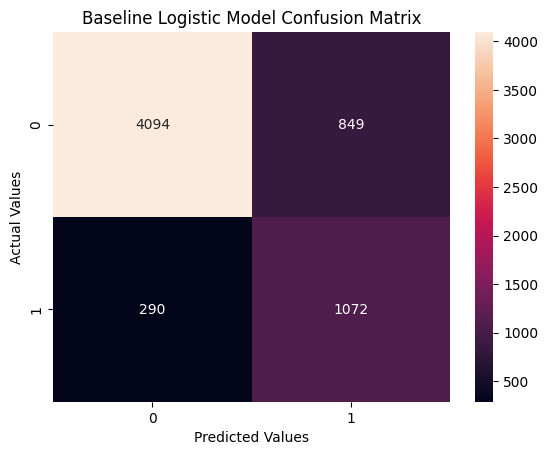

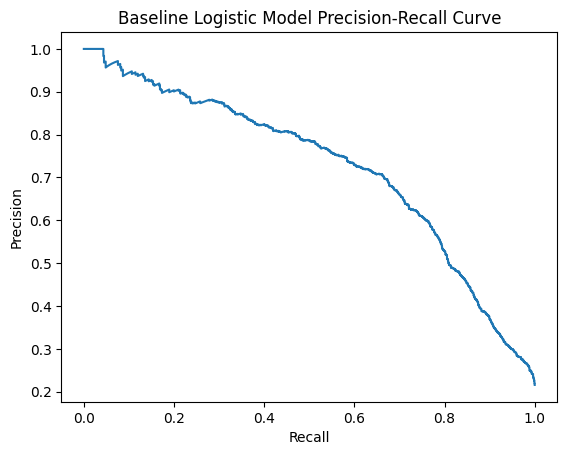

In [78]:
evaluate_model("Baseline Logistic Model", baseline_model, X_test, y_test)

Accuracy: 0.94
Precision: 0.97
Recall: 0.73
F1: 0.83

XGBoost Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4943
           1       0.97      0.73      0.83      1362

    accuracy                           0.94      6305
   macro avg       0.95      0.86      0.90      6305
weighted avg       0.94      0.94      0.93      6305



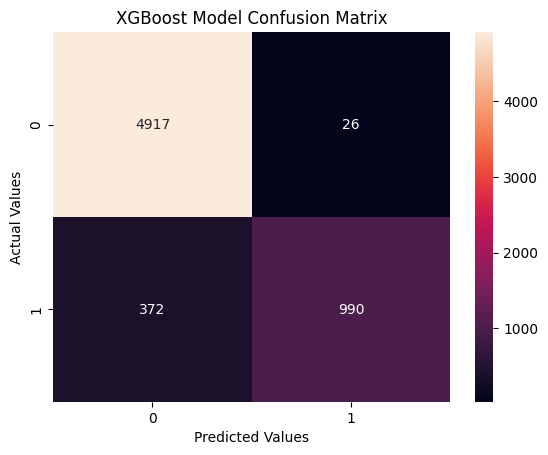

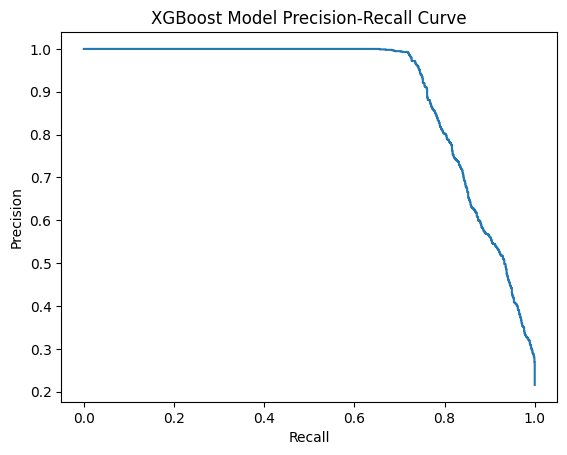

In [79]:
# Evaluate the XGBoost Model
evaluate_model("XGBoost Model", xg_model, X_test, y_test)

In [80]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth": randint(3, 9),
    "classifier__learning_rate": uniform(0.01, 0.49),
    "classifier__subsample": uniform(0.6, 0.4),
    "classifier__colsample_bytree": uniform(0.6, 0.4),
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0, 5)
}

In [81]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1,
    random_state=42
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('impute',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length'...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7f3957894830>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7f3957994510>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7f39578943b0>},
                   random_state=42, scoring='average_precision', verbose=1)

In [82]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.6806509280190978),
 'classifier__gamma': np.float64(0.8182797143285225),
 'classifier__learning_rate': np.float64(0.09049024098618653),
 'classifier__max_depth': 7,
 'classifier__min_child_weight': 3,
 'classifier__n_estimators': 528,
 'classifier__subsample': np.float64(0.8535034254880709)}

In [83]:
random_search.best_score_

np.float64(0.904325554689477)

Accuracy: 0.94
Precision: 0.96
Recall: 0.75
F1: 0.84

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4943
           1       0.96      0.75      0.84      1362

    accuracy                           0.94      6305
   macro avg       0.95      0.87      0.90      6305
weighted avg       0.94      0.94      0.94      6305



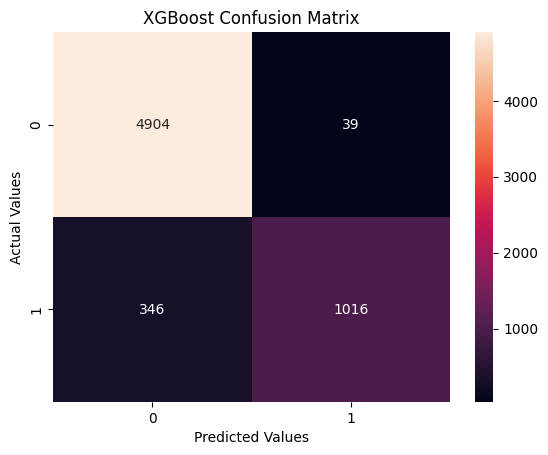

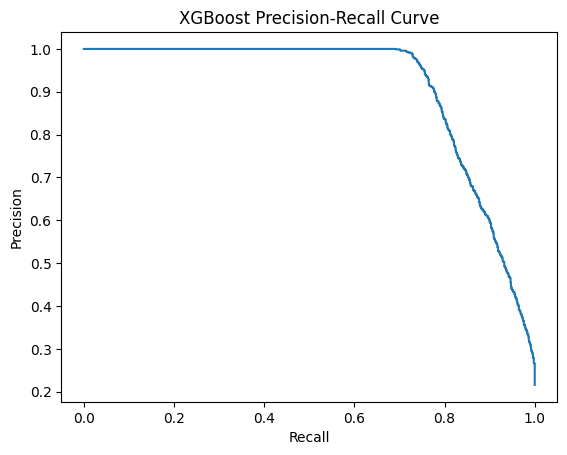

In [84]:
#Passing the XGBoost model after performing Hyperparameter Tuning
evaluate_model("XGBoost", random_search, X_test, y_test)

In [85]:
# 1. Extract the best tuned pipeline from RandomizedSearchCV
best_model = random_search.best_estimator_

# 2. Calibrate the tuned model
from sklearn.calibration import CalibratedClassifierCV
calibrated_model = CalibratedClassifierCV(best_model, method="sigmoid", cv=5)
calibrated_model.fit(X_train, y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('impute',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('inpute',
                                                                                                    SimpleImputer(f...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.09049024098618653),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=7,
                                                                max_leaves=None,
                                                                min_child_weight=3,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=528,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [86]:
import joblib

joblib.dump(calibrated_model, "credit_risk_model.pkl")

['credit_risk_model.pkl']

['credit_risk_model.pkl']

In [87]:
import joblib
model = joblib.load("credit_risk_model.pkl")